In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("car_prediction_100.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (100, 12)


,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Previous_Owners,Engine_CC,Mileage_KMPL,Color,Selling_Price_INR
0,1,Hyundai,i20,2015,105196,Diesel,Manual,1,1197,22.3,White,150000
1,2,Nissan,Magnite,2021,12165,Petrol,Manual,1,1197,19.1,Silver,561000
2,3,Renault,Kiger,2021,36893,Diesel,Automatic,1,1997,23.3,Black,527000
3,4,Tata,Nexon,2020,21396,Petrol,Automatic,1,1199,23.9,Silver,526000
4,5,Kia,Sonet,2023,24361,Diesel,Manual,3,1199,23.6,Grey,623000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_ID             100 non-null    int64  
 1   Brand              100 non-null    str    
 2   Model              100 non-null    str    
 3   Year               100 non-null    int64  
 4   Kilometers_Driven  100 non-null    int64  
 5   Fuel_Type          100 non-null    str    
 6   Transmission       100 non-null    str    
 7   Previous_Owners    100 non-null    int64  
 8   Engine_CC          100 non-null    int64  
 9   Mileage_KMPL       100 non-null    float64
 10  Color              100 non-null    str    
 11  Selling_Price_INR  100 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 9.5 KB


In [4]:
df.isnull().sum()

Car_ID               0
Brand                0
Model                0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Previous_Owners      0
Engine_CC            0
Mileage_KMPL         0
Color                0
Selling_Price_INR    0
dtype: int64

In [5]:
df.describe()

,Car_ID,Year,Kilometers_Driven,Previous_Owners,Engine_CC,Mileage_KMPL,Selling_Price_INR
count,100.000000,100.000000,100.000000,100.00000,100.000000,100.00000,1.000000e+02
mean,50.500000,2019.980000,63155.930000,2.05000,1399.790000,19.46100,4.523500e+05
std,29.011492,3.437699,32856.902271,0.79614,331.987382,3.96339,2.649976e+05
min,1.000000,2015.000000,9330.000000,1.00000,998.000000,12.00000,1.500000e+05
25%,25.750000,2017.000000,36339.750000,1.00000,1197.000000,16.02500,2.167500e+05
50%,50.500000,2020.500000,65045.500000,2.00000,1199.000000,19.55000,4.195000e+05
75%,75.250000,2023.000000,92488.000000,3.00000,1598.000000,22.72500,6.450000e+05
max,100.000000,2025.000000,119635.000000,3.00000,1997.000000,26.00000,1.242000e+06


In [6]:
X = df[
    [
        "Brand",
        "Model",
        "Year",
        "Kilometers_Driven",
        "Fuel_Type",
        "Transmission",
        "Previous_Owners",
        "Engine_CC",
        "Mileage_KMPL",
        "Color"
    ]
]

y = df["Selling_Price_INR"]

In [7]:
categorical_features = [
    "Brand",
    "Model",
    "Fuel_Type",
    "Transmission",
    "Color"
]

In [8]:
numerical_features = [
    "Year",
    "Kilometers_Driven",
    "Previous_Owners",
    "Engine_CC",
    "Mileage_KMPL"
]

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [10]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [13]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Brand','Model','Year',...,'Engine_CC','Mileage_KMPL','Color']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated wi

In [14]:
y_pred = model.predict(X_test)

In [15]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print(f"MAE  : ₹{mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : ₹{rmse:,.2f}")
print(f"R²   : {r2:.4f}")

MAE  : ₹50,440.10
MSE  : 3,476,906,354.10
RMSE : ₹58,965.30
R²   : 0.9575


In [16]:
comparison = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred.round(0)
})

comparison.head(10)

,Actual_Price,Predicted_Price
0,870000,841346.0
1,585000,594617.0
2,429000,437141.0
3,1158000,1129087.0
4,333000,371681.0
5,150000,162278.0
6,757000,724427.0
7,842000,765345.0
8,976000,921930.0
9,150000,86570.0


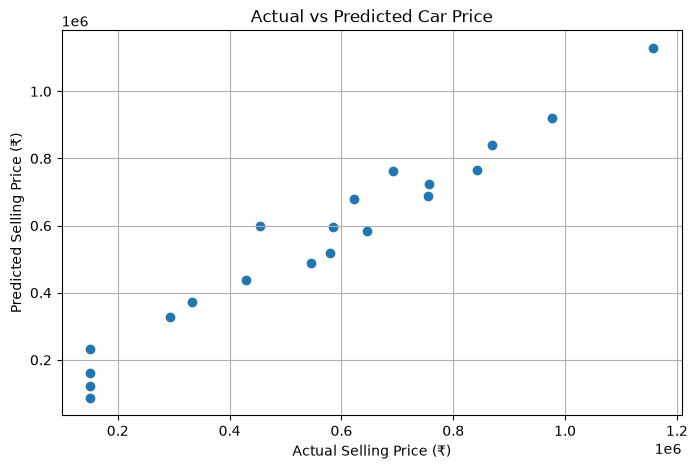

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title("Actual vs Predicted Car Price")

plt.grid(True)
plt.show()

In [18]:
new_car = pd.DataFrame([{
    "Brand": "Hyundai",
    "Model": "Creta",
    "Year": 2022,
    "Kilometers_Driven": 30000,
    "Fuel_Type": "Petrol",
    "Transmission": "Automatic",
    "Previous_Owners": 1,
    "Engine_CC": 1497,
    "Mileage_KMPL": 17.5,
    "Color": "White"
}])

In [19]:
predicted_price = model.predict(new_car)[0]

print(f"Predicted car price: ₹{predicted_price:,.0f}")

Predicted car price: ₹1,026,115


In [21]:
import joblib

joblib.dump(model, "car_price_model.pkl")

['car_price_model.pkl']